In [ ]:
# Last edited by Nana Kiziriya on July 8, 2026
# Originally developed on Google Colab, regularly uploaded to GitHub

# NOTE: June 22, 2026
# Abstract parent class for CRN models
# Subclasses: Kurchak1, Boateng1, FinkeWatzky (GitHub)
# Fit testing

In [ ]:
#@title Imports
#@markdown

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

!pip install lmfit -q
from lmfit import Model, Parameter, Parameters, minimize, report_fit
from scipy.integrate import solve_ivp

import inspect
import datetime as dt

from pandas.api.types import is_list_like   # list, tuple, series, NOT string
from pandas.api.types import is_dict_like
from abc import ABC, abstractmethod

In [ ]:
#@title (DEPR. v.1) CRN Model
#@markdown *abstract superclass*

class DEPR_CRNModel(Model,ABC) :

  model_cnt=0

  '''
  lmfit.Model plus:
  > Time
    - independent_vars = 't_eval'
    - self.t_eval stores ordered list-like of times that need to be evaluated for fitting, plotting, etc.
  > Parameters
    - self.params (type lmfit.Parameters) for storing fitted vals
      - set in __init__
      - automatically nonnegative
      - lmfit.Model self.make_params() is not stored instance var
    - self.__init__ argument 'param_names' can either be dict-like or list-like
      e.g. param_names = {'j':2,'k':3} equivalent to param_names = ('j0','j1','k0','k1','k2')
  '''


  def __init__(self,
               t_eval, emp_data, emp_params:Parameters,   # self
               name=None) :              # super

    # argument validation
    assert is_list_like(t_eval), f'\'t_eval\' should be list-like: time measurements \nInvalid input: {t_eval}'
    assert is_list_like(emp_data), f'\'emp_data\' should be list-like: data measurements over time \nInvalid input: {emp_data}'

    temp_pnames = inspect.signature(self.func).parameters
    # if 'self' in temp_pnames : temp_pnames.pop(0)
    # assert 'self' not in temp_pnames, f'\'self\' failed to be removed from \'param_names\''

    assert set(emp_params.valuesdict().keys()).issubset(temp_pnames), f'\'emp_params\':Parameters argument should only define \'func\':callable parameters \nInvalid input: {set(emp_params.valuesdict().keys()).difference(temp_pnames)}'

    self.t_eval = t_eval
    self.emp_data = emp_data
    self.emp_params = emp_params

    if not name :
      name = f'CRNModel_{model_cnt}'
      model_cnt+=1

    # super constructor
    super().__init__(self.func,
                     independent_vars=['t'],
                     name=name)

  @abstractmethod
  # subclass must only implement parameters to be fit (excl. 'self', time 't')
  def func(self,t,*args,**kwargs):
    pass

  def fit(self,weights=None) :
    return super().fit(self.emp_data,params=self.emp_params,t=self.t_eval,weights=weights)


In [ ]:
#@title (DEPR. v.1) Boateng1_revAB Model [MID]
#@markdown A<->B . . . AB<->B

class DEPR_Boateng1Model_revAB(CRNModel) :

  model_cnt = 0

  def __init__(self,
               t_eval, emp_data,        # super
               IVs_value,             # self
               IVs_vary,              # self
               IVs_min,               # self
               IVs_max,               # self
               name=None,               # super
               method='Radau'):        # self

    self.method = method

    # argument validation
    assert is_list_like(t_eval) , f'{type(self)}.__init__ argument \'t_eval\' must be list-like.'
    assert is_list_like(emp_data) , f'{type(self)}.__init__ argument \'emp_data\' must be list-like.'

    if not name :
      name = f'Boateng1Model_revAB_{model_cnt}'
      model_cnt+=1

    # Set empirical limits on Parameters
    # (name, value=None, vary=True, min=-inf, max=inf, expr=None, brute_step=None)
    emp_params = Parameters()

    # 6 PARAMS
    _param_names = ['k1','k2','k4','k5','fl_B','A_init']

    # DEFAULTS:
    IVs_value[-1] = emp_data[0] # smart auto A_init
    # smart auto k1 (also recalculated at every iteration in this.fit())
    IVs_value[_param_names.index('k1')] = (
        (emp_data[0]-np.average(emp_data[1:4]))
        / ((t_eval[0]-np.average(t_eval[1:4]))
          * emp_data[0]
          * (IVs_value[_param_names.index('fl_B')]-1)))
    _IVs_vary = [False,True,True,True,True,False]
    _IVs_min = [0,0,0,0,1,np.max([IVs_value[-1]-100,1])] # auto A_init
    _IVs_max = [2,2,2,2,None,IVs_value[-1]+100] # auto A_init

    for i in range(len(_param_names)):
      emp_params.add(
          _param_names[i],
          value = IVs_value[i] if IVs_value[i] else 0,
          vary = IVs_vary[i] if IVs_vary[i]!=None else _IVs_vary[i],
          min = IVs_min[i] if IVs_min[i] else _IVs_min[i],
          max = IVs_max[i] if IVs_max[i] else _IVs_max[i]
          )

    # super constructor
    super().__init__(t_eval = t_eval,
                     emp_data = emp_data,
                     emp_params = emp_params,
                     name = name)

  def func(self,t, k1,k2,k4,k5, fl_B,A_init):
    t = np.asarray(t)
    t_span = (t[0], t[-1])

    def rhs(T, y):
      A = y[0]
      B = A_init - A

      dAdt = B*(k4+k5*B) -A*(k1+k2*B)

      return [dAdt]

    # default 'RK45', alt 'BDF' 'RK23' 'DOP853' 'Radau' 'LSODA'
    sol = solve_ivp(rhs, t_span, y0 = [A_init],
        dense_output=True, atol=1e-6, rtol=1e-6, method=self.method)

    if not sol.success:
        raise RuntimeError("ODE solver failed: " + sol.message)

    Y = sol.sol(t)
    return Y[0] + fl_B*(A_init-Y[0])

  def fit(self,weights=None) :
    self.emp_params['k1'].set(value=
      (self.emp_data[0]-np.average(self.emp_data[1:4])) / ((self.t_eval[0]-np.average(self.t_eval[1:4])) * self.emp_data[0] * (self.emp_params['fl_B']-1))
      )
    return super().fit(weights=weights)

In [ ]:
#@title (DEPR. v.1) Boateng1_revABC Model [BETTER]
#@markdown A<->B . . . AB<->B . . . B<->C

class DEPR_Boateng1Model_revABC(CRNModel) :

  model_cnt = 0

  def __init__(self,
               t_eval, emp_data,        # super
               IVs_value,             # self
               IVs_vary,              # self
               IVs_min,               # self
               IVs_max,               # self
               name=None,               # super
               method='Radau'):        # self
              #  do_smart_param=True):  # self

    self.method = method
    # self.do_smart_param = do_smart_param

    # argument validation
    assert is_list_like(t_eval) , f'{type(self)}.__init__ argument \'t_eval\' must be list-like.'
    assert is_list_like(emp_data) , f'{type(self)}.__init__ argument \'emp_data\' must be list-like.'

    if not name :
      name = f'Boateng1Model_revABC_{model_cnt}'
      model_cnt+=1


    # Set empirical limits on Parameters
    # (name, value=None, vary=True, min=-inf, max=inf, expr=None, brute_step=None)
    emp_params = Parameters()

    # 9 PARAMS
    _param_names = ['k0','k1','k2','k3','k4','k5','fl_B','fl_C','A_init']

    # DEFAULTS:
    IVs_value[-1] = emp_data[0] # smart auto A_init
    # smart auto k1 (also recalculated at every iteration in this.fit())
    IVs_value[_param_names.index('k1')] = (
        (emp_data[0]-np.average(emp_data[1:4]))
        / ((t_eval[0]-np.average(t_eval[1:4]))
          * emp_data[0]
          * (IVs_value[_param_names.index('fl_B')]-1)))
    _IVs_vary = [True,False,True,True,True,True,True,True,False]
    _IVs_min = [0,0,0,0,0,0,1,1,np.max([IVs_value[-1]-100,1])] # auto A_init
    _IVs_max = [2,2,2,2,2,2,None,None,IVs_value[-1]+100] # auto A_init

    for i in range(len(_param_names)):
      emp_params.add(
          _param_names[i],
          value = IVs_value[i] if IVs_value[i] else 0,
          vary = IVs_vary[i] if IVs_vary[i]!=None else _IVs_vary[i],
          min = IVs_min[i] if IVs_min[i] else _IVs_min[i],
          max = IVs_max[i] if IVs_max[i] else _IVs_max[i]
          )

    # smart auto k1 (also recalculated at every iteration in this.fit())
    emp_params['k1'].set(value=
        ((emp_data[0]-np.average(emp_data[1:4])) / ((t_eval[0]-np.average(t_eval[1:4])) * emp_data[0] * (emp_params['fl_B']-1)))
        )

    # super constructor
    super().__init__(t_eval = t_eval,
                     emp_data = emp_data,
                     emp_params = emp_params,
                     name = name)

  # def func(self,t, k0,k1,k2,k3,k4,k5, fl_A,fl_B,fl_C, A_init,B_init):
  def func(self,t, k0,k1,k2,k3,k4,k5, fl_B,fl_C, A_init):
    t = np.asarray(t)
    t_span = (t[0], t[-1])

    def rhs(T, y):
      A,C = y
      B = (A_init) - (A+C)

      dAdt = B*(k4 - k2*A + k5*B) - k1*A
      dCdt = k0*B - k3*C

      return [dAdt, dCdt]

    # default 'RK45', alt 'BDF' 'RK23' 'DOP853' 'Radau' 'LSODA'
    sol = solve_ivp(rhs, t_span, y0 = [A_init,0],
        dense_output=True, atol=1e-6, rtol=1e-6, method=self.method)

    if not sol.success:
        raise RuntimeError("ODE solver failed: " + sol.message)

    Y = sol.sol(t)
    # return fl_A*Y[0] + fl_B*((A_init+B_init)-(Y[0]+Y[1])) + fl_C*Y[1]
    return Y[0] + fl_B*((A_init)-(Y[0]+Y[1])) + fl_C*Y[1]



  def fit(self,weights=None) :
    self.emp_params['k1'].set(value=
      (self.emp_data[0]-np.average(self.emp_data[1:4])) / ((self.t_eval[0]-np.average(self.t_eval[1:4])) * self.emp_data[0] * (self.emp_params['fl_B']-1))
      )
    return super().fit(weights=weights)

# k0 - 2nd aggregation
        #  0.65318482,
        #  0.48425692,
        #  0.36232351,
        #  0.62442928,
# k1 - nucleation
# k2 - 1st aggregation
        #  0.00227267,
        #  0.00183510,
        #  0.00185061,
        #  0.00123468,
# k3 - rev. 2nd aggr
        #  0.01734594,
        #  0.01732002,
        #  0.02786812,
        #  0.01744533,
# k4 - rev nucl.
        #  0.31758925,
        #  0.23546005,
        #  0.71788164,
        #  0.00675550,
# k5 - rev aggr.
        #  3.8570e-09,
        #  8.6343e-10,
        #  0.00489408,
# fl_B
# fl_C
# A_init - total conc

# Tautology:
  # fl_A==1
  # B_init==0 (assumption)
  # C_init==0 (assumption)

# **UPDATED MODEL CLASSES**

In [ ]:
#@title CRN Model
# 1 dimensional, given eval times 't'
@markdown *abstract superclass*

# solve_ivp() : fun, t_span, y0, method='RK45', t_eval=None, dense_output=False                                   [optional, for subclass func()]
# Model :       func, independent_vars=None, param_names=None, nan_policy='raise', prefix='', name=None, **kws
# Model.fit :   data, params=None, weights=None, ..., iter_cb=None, scale_covar=True, verbose=False, fit_kws=None, nan_policy=None, calc_covar=True, max_nfev=None, coerce_farray=True, **kwargs)
# self :        t, emp_data
# cls :         param_attr, parse_param_init()

!pip install lmfit -q
from lmfit import Parameter, Parameters, # minimize, report_fit, Model

class CRNModel(Model,ABC) :

  # name, value, vary, min, max, expr, ...
  _param_attr = Parameter.__init__.__code__.co_varnames[1:]

  @property
  def model_versions(cls){
      raise NotImplementedError('If model class implements multi-versioning, must assign model_versions = (list-like of model\'s versions\' keywords)')
  }

  @property
  def param_names(cls){
      raise NotImplementedError('Must assign param_names = (str list-like of this model\'s parameter names)')
  }

  @property
  def t(self){
      raise NotImplementedError('Must assign self.t = (number list-like of times to evaluate model at)')
  }

  @abstractmethod
  def func(self,t,*args,**kwargs):
    raise NotImplementedError('Must implement func(self,t,*param_names) -> (list-like of outputs)')

  def __init__(self, t, data, emp_params:Parameters):

  #   # argument validation
  #   assert is_list_like(t_eval), f'\'t_eval\' should be list-like: time measurements \nInvalid input: {t_eval}'
  #   assert is_list_like(emp_data), f'\'emp_data\' should be list-like: data measurements over time \nInvalid input: {emp_data}'

  #   temp_pnames = inspect.signature(self.func).parameters
  #   # if 'self' in temp_pnames : temp_pnames.pop(0)
  #   # assert 'self' not in temp_pnames, f'\'self\' failed to be removed from \'param_names\''

  #   assert set(emp_params.valuesdict().keys()).issubset(temp_pnames), f'\'emp_params\':Parameters argument should only define \'func\':callable parameters \nInvalid input: {set(emp_params.valuesdict().keys()).difference(temp_pnames)}'

  #   self.t_eval = t_eval
  #   self.emp_data = emp_data
  #   self.emp_params = emp_params

  #   if not name :
  #     name = f'CRNModel_{model_cnt}'
  #     model_cnt+=1

  #   # super constructor
  #   super().__init__(self.func,
  #                    independent_vars=['t'],
  #                    name=name)

  # def fit(self,weights=None) :
  #   return super().fit(self.emp_data,params=self.emp_params,t=self.t_eval,weights=weights)

  def parse_param_init(self,str):


(1, 2, 'k0', 'k1', 'k2')

In [ ]:
#@title Boateng System Model
@markdown

class BoatengSysMod_revABC2(CRNModel) :

  model_versions = ('rAB','rABC1','rABC2','rABC3')
  params_name = ('A_init','fl_B','fl_C',*tuple(f'k{i}' for i in range(8)))
  param_required = {
    name
    value :
      (),
    vary :
      (),
    min :
      (),
    max :
      (),
  }

  def __init__(self,
               model_version,               # self
               t_eval, emp_data,        # super
               IV_str:str=None,     # s...?
               method='Radau'):             # self

    self.method = method
    # self.do_smart_param = do_smart_param

    # argument validation
    assert is_list_like(t_eval) , f'{type(self)}.__init__ argument \'t_eval\' must be list-like.'
    assert is_list_like(emp_data) , f'{type(self)}.__init__ argument \'emp_data\' must be list-like.'

    if not name :
      name = f'Boateng1Model_revABC_{model_cnt}'
      model_cnt+=1


    # Set empirical limits on Parameters
    # (name, value=None, vary=True, min=-inf, max=inf, expr=None, brute_step=None)
    emp_params = Parameters()

    # 9 PARAMS


    # DEFAULTS:
    IVs_value[-1] = emp_data[0] # smart auto A_init
    # smart auto k1 (also recalculated at every iteration in this.fit())
    IVs_value[_param_names.index('k1')] = (
        (emp_data[0]-np.average(emp_data[1:4]))
        / ((t_eval[0]-np.average(t_eval[1:4]))
          * emp_data[0]
          * (IVs_value[_param_names.index('fl_B')]-1)))
    _IVs_vary = [True,False,True,True,True,True,True,True,False]
    _IVs_min = [0,0,0,0,0,0,1,1,np.max([IVs_value[-1]-100,1])] # auto A_init
    _IVs_max = [2,2,2,2,2,2,None,None,IVs_value[-1]+100] # auto A_init

    for i in range(len(_param_names)):
      emp_params.add(
          _param_names[i],
          value = IVs_value[i] if IVs_value[i] else 0,
          vary = IVs_vary[i] if IVs_vary[i]!=None else _IVs_vary[i],
          min = IVs_min[i] if IVs_min[i] else _IVs_min[i],
          max = IVs_max[i] if IVs_max[i] else _IVs_max[i]
          )

    # smart auto k1 (also recalculated at every iteration in this.fit())
    emp_params['k1'].set(value=
        ((emp_data[0]-np.average(emp_data[1:4])) / ((t_eval[0]-np.average(t_eval[1:4])) * emp_data[0] * (emp_params['fl_B']-1)))
        )

    # super constructor
    super().__init__(t_eval = t_eval,
                     emp_data = emp_data,
                     emp_params = emp_params,
                     name = name)

  # def func(self,t, k0,k1,k2,k3,k4,k5, fl_A,fl_B,fl_C, A_init,B_init):
  def func(self,t, k0,k1,k2,k3,k4,k5, fl_B,fl_C, A_init):
    t = np.asarray(t)
    t_span = (t[0], t[-1])

    def rhs(T, y):
      A,C = y
      B = (A_init) - (A+C)

      dAdt = B*(k4 - k2*A + k5*B) - k1*A
      dCdt = k0*B - k3*C

      return [dAdt, dCdt]

    # default 'RK45', alt 'BDF' 'RK23' 'DOP853' 'Radau' 'LSODA'
    sol = solve_ivp(rhs, t_span, y0 = [A_init,0],
        dense_output=True, atol=1e-6, rtol=1e-6, method=self.method)

    if not sol.success:
        raise RuntimeError("ODE solver failed: " + sol.message)

    Y = sol.sol(t)
    # return fl_A*Y[0] + fl_B*((A_init+B_init)-(Y[0]+Y[1])) + fl_C*Y[1]
    return Y[0] + fl_B*((A_init)-(Y[0]+Y[1])) + fl_C*Y[1]

  def fit(self,weights=None) :
    self.emp_params['k1'].set(value=
      (self.emp_data[0]-np.average(self.emp_data[1:4])) / ((self.t_eval[0]-np.average(self.t_eval[1:4])) * self.emp_data[0] * (self.emp_params['fl_B']-1))
      )
    return super().fit(weights=weights)


#
# **FITTING / TESTING**

NOTES: DIAGNOSING PROBLEMS IN THIS ORDER

1. do not normalize all the way down to 0-1. Perhaps keep it at pre-scaled average. avoids unnecessarily stiff solve. parameters are most likely scalable (confirm)

2. if solve_ivp has trouble, try changing solver, adjusting init values to avoid a spurious solution, or change Parameter max to something lower than infinity

### ***RUN ONCE (x1)***

In [ ]:
directory = '/content/' # @param ['/content/','/content/Fit_Data/'] {allow-input: true}
filename = 'AmK9_R9_SHEET-Raw-data_DROPg1g0_CLEANDATA_tr3-0_2026_8_4_62417.xlsx' # @param ['AmK9_R9_SHEET-Raw-data_DROPg1g0_CLEANDATA_tr3-0_2026_8_4_62417.xlsx'] {allow-input: true}

result_subdir = 'Fit_Data' # @param ['Fit_Data'] {allow-input: true}

data_file = f'{directory}{filename}'
!mkdir $result_subdir

#@markdown **Converts file to pandas dataframe*

In [ ]:
fit_data_index = 19 #@param {type:'integer'}
#@markdown **Enter next empty index in Fit Data spreadsheet (GDrive)*

In [ ]:
#@markdown Parsing data

df_trials = pd.read_excel(data_file)
is_clean = 'CLEANDATA' in data_file

# Extract time column into a series
ser_time = df_trials.pop(df_trials.columns[0])
# ser_time.div(60*60) # sec->min->hours (boateng)
# already processed data

In [ ]:
model_ver = 'revAB' #@param ['revABC','revAB']
#@markdown **revABC recommended*

In [ ]:
#@markdown Opening fit stats dataframe

#@markdown **columns e.g: Index . Trial . Grade . Plot ... Stats/Diagnostics ... Final Values ... Inital Values . Model ...
fit_stats_df = None

fit_stats_df = pd.DataFrame(columns=[
    '#',
    'Trial',
    'Model',
    'Grade',
    'Plot',
    'Equilibrium',
    'R2', 'BIC', 'AIC', 'rChi2', 'Chi2',
    'k0', 'k1', 'k2', 'k3', 'k4', 'k5',
    'fl_B', 'fl_C', 'A_init',
    'IVs_value',
    'IVs_vary',
    'IVs_min',
    'IVs_max',
    'method',
    'apply_weights',
    ])


In [ ]:
#@markdown Available Trials:
# print(Available Trials:)
print(list(df_trials.columns))

['0.9', '0.8', '0.7', '0.6', '0.5', '0.4', '0.3', '0.2', '0.1']


### ***RUN FOR EACH FIT***

In [ ]:
#@markdown Trigger before last fit:

is_last_fit = False #@param {type:'boolean'}

#@markdown *default: *False*

#@markdown **After storing last fit, triggers .xlsx export and clears DataFrame.*

In [ ]:
# default 'RK45', alt 'BDF' 'RK23' 'DOP853' 'Radau' 'LSODA'
# https://docs.scipy.org/doc/scipy/reference/generated/scipy.integrate.solve_ivp.html#:~:text=methodstr


trial = '0.4' #@param{type:'string'}
trial_index = df_trials.columns.get_loc(trial)
#@markdown
num_method = 'RK45' #@param ['Radau','RK45','BDF','RK23','DOP853','LSODA']
#@markdown **numerical method: Radau, RK45, BDF, etc.*


In [ ]:
#@markdown Initial Parameter Values & Varies

#@markdown **k0->k5 fl_A fl_B A_init*

#@markdown **all autos are done in model class, except A_init IVs_value*

#@markdown **Updated IVs (e.g. auto, default) will be recorded*

#@markdown ...
IVs_value = [1, 0.001, 0.7, 0.003, 330, 250] #@param
IVs_value[-1] = df_trials[trial][0]
#@markdown **list non-neg nums : auto k1 A_init ("None"), must enter all else*

#@markdown ...
IVs_vary = [True,True,True,True,False,False] #@param
if IVs_vary==None:
  IVs_vary=[None]*9;
#@markdown **list booleans : all auto default if "None"*

#@markdown ...
IVs_min = None #@param
if IVs_min==None:
  IVs_min=[None]*9;
IVs_max = None #@param
if IVs_max==None:
  IVs_max=[None]*9;
#@markdown **lists non-neg num containing value : all auto default if "None", w/ smart default A_init+/-100*


In [ ]:
# df_fits

weights=None
apply_weights=False #@param {type:'boolean'}

#@markdown *default: *False*

#@markdown **negligible effect on higher magnitude trials; might help prevent convergence to bad fits?*

#@markdown **quadratic dist. (hardcoded)*
if(apply_weights) :
  N=ser_time.shape[0]
  weights=(np.array(range(N))-N/2)**2 # quadratic dist
  avg_weight=np.average(weights)
  weights=weights/avg_weight

In [ ]:
#@markdown initialize model

#@markdown **hardcoded model args: name, method*

model = None

if model_ver=='revABC':
  model = Boateng1Model_revABC(
      t_eval=ser_time.tolist(),
      emp_data=df_trials.iloc[:,trial_index].tolist(),
      IVs_value=IVs_value,
      IVs_vary=IVs_vary,
      IVs_min=IVs_min,
      IVs_max=IVs_max,
      name='Boateng1_revABC',
      method=num_method)

elif model_ver=='revAB':
  model = Boateng1Model_revAB(
      t_eval=ser_time.tolist(),
      emp_data=df_trials.iloc[:,trial_index].tolist(),
      IVs_value=IVs_value,
      IVs_vary=IVs_vary,
      IVs_min=IVs_min,
      IVs_max=IVs_max,
      name=f'Boateng1_revAB',
      method=num_method)

  print('Warning: suboptimal model in use.')

In [ ]:
#@markdown Calculate and display fit:
result = model.fit(weights=weights)
result

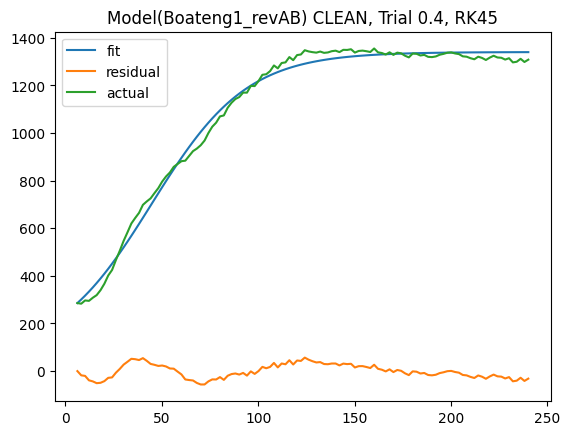

In [ ]:
#@markdown Plot & save img:

def plot_model_result(model, result) :
  plt.plot(model.t_eval,result.best_fit,label="fit")
  plt.plot(model.t_eval,result.residual,label="residual")
  plt.plot(model.t_eval,model.emp_data,label="actual")
  plt.title(f'{model.name} {'' if is_clean else 'UN'}CLEAN, Trial {trial}, {model.method}')
  plt.legend()
  plt.savefig(f'{directory}{result_subdir}/{fit_data_index}.png')
  plt.show()

plot_model_result(model,result)

In [ ]:
#@title Extrapolate Equilibrium to (num_dec) decimal places
#@markdown start @10k datapoints, STOP when at least half the datapoints are equal (after rounding)

# Test if too slow:
# result.eval(t=range(10000))[-20,-1]

def extrapolate_equilibrium(result) :
  num_datapnts = 10000
  num_dec = "0" #@param[4,3,2,1,0,-1]
  num_dec = int(num_dec)
  #@markdown **default 4; 1 for rk45 revAB trial 0.7, fit index >=14*

  while(True) :
    trial_time = np.array(range(num_datapnts))
    extrapolate = np.round(result.eval(t=trial_time), num_dec)
    checklen = (np.where(extrapolate==extrapolate[-1]))[0]
    if len(checklen)*2>=len(extrapolate) :

      print('\nEQUILIBRIUM:')
      print(extrapolate[-1])
      print(extrapolate)
      return extrapolate[-1]
    else :
      num_datapnts*=2

equilibrium = extrapolate_equilibrium(result)


EQUILIBRIUM:
1340.0
[ 286.  293.  301. ... 1340. 1340. 1340.]


In [ ]:
#@markdown store stats in df

final_values = list(result.best_values.values()) # k0->k5, fl_B, fl_C, A_init (unpack list)
if model_ver=='revAB':
  final_values.insert(0,'') # k0 blank
  final_values.insert(3,'') # k3 blank
  final_values.insert(7,'') # fl_C blank

fit_stats_df.loc[fit_stats_df.shape[0]] = [
    fit_data_index,        # (index #)
    trial,            # Trial
    model_ver,        # Model
    '',               # Grade
    '-',                # Plot
    equilibrium,        # Equilibrium
    result.rsquared,  # R2
    result.bic,       # BIC
    result.aic,       # AIC
    result.redchi,    # rChi2
    result.chisqr,    # Chi2
    *final_values,     # best fit params
    list(result.init_values.values()),                  # IVs_value
    [p.vary for p in model.emp_params.values()],        # IVs_vary
    [float(p.min) for p in model.emp_params.values()],  # IVs_min
    [float(p.max) for p in model.emp_params.values()],  # IVs_max
    model.method,     # method (of approximation, not r. minimization)
    apply_weights,    # apply_weights
]

fit_data_index+=1;

In [ ]:
#@markdown if *is_last_fit* : export and clear df
force_save = True #@param{type:'boolean'}
if is_last_fit or force_save:
  rtfn = dt.datetime.now()
  rtfn = f'_{rtfn.year}_{rtfn.month}_{rtfn.day}_{rtfn.hour}{rtfn.minute}{rtfn.second}'
  fit_stats_df.to_excel(f'{directory}{result_subdir}/fit_stats{rtfn}.xlsx',index=False)
  fit_stats_df = pd.DataFrame()

  # for zipping in google colab for easy download
  !zip -r /content/fit_data.zip /content/Fit_Data


  adding: content/Fit_Data/ (stored 0%)
  adding: content/Fit_Data/29.png (deflated 7%)
  adding: content/Fit_Data/22.png (deflated 7%)
  adding: content/Fit_Data/32.png (deflated 7%)
  adding: content/Fit_Data/30.png (deflated 7%)
  adding: content/Fit_Data/28.png (deflated 7%)
  adding: content/Fit_Data/24.png (deflated 7%)
  adding: content/Fit_Data/27.png (deflated 7%)
  adding: content/Fit_Data/23.png (deflated 8%)
  adding: content/Fit_Data/21.png (deflated 7%)
  adding: content/Fit_Data/fit_stats_2026_10_8_19341.xlsx (deflated 7%)
  adding: content/Fit_Data/20.png (deflated 6%)
  adding: content/Fit_Data/31.png (deflated 7%)
  adding: content/Fit_Data/25.png (deflated 7%)
  adding: content/Fit_Data/26.png (deflated 7%)
  adding: content/Fit_Data/19.png (deflated 7%)


#
# **ITERATIVE PARAM ADJUSTMENT**
_revABC only

In [ ]:
execute = False #@param {type:'boolean'}

In [ ]:
#@markdown Trigger before last fit:
if execute :
  is_last_fit = False #@param {type:'boolean'}

#@markdown *default: *False*

#@markdown **After storing last fit, triggers .xlsx export and clears DataFrame.*

In [ ]:
#@title Iterative param adjustment, AFTER 1st good fit
#@markdown
if execute :

  # INPUTS HERE ###################
  param2target = [
      # ('fl_B',75),
      # ('fl_C',100),
      ]
  vary = ['fl_C']
  num_iter = 10 # higher -> more time, but more likely to fit well
  rsquared_min = 0.994 # .998 best, .996 mediocre
  #################################

  for _ in vary :
    model.emp_params[_].set(vary=True)

  # dicts from model.emp_params index to: param name, increments
  DIPI = {
      model.param_names.index(p) :
      (p,(t-result.summary()['params'][model.param_names.index(p)][1])/num_iter)
      for (p,t) in param2target
      }
  assert len(param2target)==len(DIPI)

  model_name_base = model.name

  best_result = result

  for _ in range(num_iter) :
    # adjust param init vals to last (good) result
    for i,p in enumerate(model.param_names) :
      model.emp_params[p].set(value=
          model.emp_params[p].value + DIPI[i][1]
          if i in DIPI.keys()
          else result.summary()['params'][i][1])

    result = model.fit(weights=weights)

    if result.summary()['rsquared']>=rsquared_min :
      best_result = result
      model.name = f'{model_name_base}_REFIT_v.{_+1}'
    else :
      print(f'Only {_}/{num_iter} additional good fits calculated, failed with rsq = {result.summary()['rsquared']} < {rsquared_min}')
      break

In [ ]:
#@markdown Closest adjustment:
best_result if execute else None

In [ ]:
#@markdown
if execute:
  plot_model_result(model,best_result)
  extrapolate_equilibrium(best_result)


In [ ]:
#@markdown store stats in df
if execute :
  fit_stats_df.loc[fit_stats_df.shape[0]] = [
      fit_data_index,        # (index #)
      trial,            # Trial
      model_ver,        # Model
      '',               # Grade
      'IMAGE(enterhttps, 1)',   # Plot
      equilibrium,        # Equilibrium
      result.rsquared,  # R2
      result.bic,       # BIC
      result.aic,       # AIC
      result.redchi,    # rChi2
      result.chisqr,    # Chi2
      *list(result.best_values.values()), # k0->k5, fl_B, fl_C, A_init (unpack list)
      list(result.init_values.values()),                  # IVs_value
      [p.vary for p in model.emp_params.values()],        # IVs_vary
      [float(p.min) for p in model.emp_params.values()],  # IVs_min
      [float(p.max) for p in model.emp_params.values()],  # IVs_max
      model.method,     # method (of approximation, not r. minimization)
      apply_weights,    # apply_weights
  ]

  fit_data_index+=1;

In [ ]:
#@markdown export and clear df
if execute and is_last_fit:
  rtfn = dt.datetime.now()
  rtfn = f'_{rtfn.year}_{rtfn.month}_{rtfn.day}_{rtfn.hour}{rtfn.minute}{rtfn.second}'
  fit_stats_df.to_excel(f'{directory}{result_subdir}/fit_stats{rtfn}.xlsx',index=False)
  fit_stats_df = pd.DataFrame()

  # for zipping in google colab for easy download
  !zip -r /content/fit_data.zip /content/Fit_Data

#
# **MANUAL FITTING / MODEL PLOT**

In [ ]:
execute = False #@param {type:'boolean'}

In [ ]:
#@title Manual fitting on most recently used model
#@markdown

if(execute) : # only for revAB
  plt.plot(model.t_eval,model.emp_data,label="actual")

  trial_time = np.array(model.t_eval)

  K = [
      # [1e-6,1e-7,1e-9,1e-8], # long logistic
      # [1e-6,1e-6,1e-9,1e-8], # f-w
      # [1e-4,1e-6,1e-9,1e-8], # fast log
      # [1e-4,1e-6,1e-7,1e-8], # fast log

      # [1e-6,1e-3,1e-9,1e-8], # angular
      # [1e-6,1e-3,1e-9,1e-4], # angular, lower equil

      # [1e-4,1e-12,1e-9,1e-8], # trial 1 esque
      # [1e-4,1e-12,1e-7,1e-10], # higher equil
      # [1.5e-4,1e-12,1e-3,5e-8],
      # [5e-5,1e-12,1e-7,1e-10],
      # [5e-5,1e-10,1e-7,1e-10], # ~0 diff to prev
      # [5e-5,1e-12,1e-9,1e-10], # ~0 diff to prev
      # [5e-5,1e-12,1e-7,1e-8], # lower equil than prev

      # [1.7e-4,0,1e-5,0],
      # [1.7e-4,0,1e-9,0], # higher equil
      # [1.2e-4,1,10e-5,0],

      # fnct_k1 TRUE
      # [200,5e-4,2.06e-1,3e-3],
      # [200,6e-4,2.535e-1,3e-3],
      # [200,5e-4,2.08e-1,2.8e-3],
      # [200,6e-4,2.555e-1,2.8e-3],

      # [300,6.5e-4,3e-1,2.3e-3],
      # [300,8e-4,3.655e-1,3e-3],
  # INCR fl_B -> k2:k1 higher (better/more realistic irl)
      # [500,8e-4,3.8e-1,3e-3],
      # [500,9e-4,3.92e-1,1e-2],

  # INCR k5 -> pull peak (reach equil) back --> decr k5
      # [1000,8e-4,3.8e-1,3e-3],
      # [1000,7.8e-4,3.8e-1,3e-3], # k2
      # [1000,8e-4,3.895e-1,3e-3], # k4
      # [1000,8e-4,3.8e-1,6.9e-3], # incr k5
      # incr k5 even more, adj k2 k4
      [1000,8e-4,3.8e-1,9e-3],
      [1000,8.115e-4,3.8e-1,9e-3],
      [1000,8e-4,3.745e-1,9e-3],

      # decr k5
      [1000,7.8e-4,3.8e-1,3e-3],
      [1000,7.725e-4,3.8e-1,1.5e-3],
      [1000,7.8e-4,3.835e-1,1.5e-3],

  ]

  for r in K :
    fnct_k1 = (model.emp_data[0]-np.average(model.emp_data[1:4])) / ((model.t_eval[0]-np.average(model.t_eval[1:4])) * model.emp_data[0] * (r[0]-1))

    trial_5mM = model.func(trial_time,
                        # k0=0.39136878,
                        k1=fnct_k1,
                        k2=r[1],
                        # k3=0.03680361,
                        k4=r[2],
                        k5=r[3],
                        fl_A=1,fl_B=r[0],
                        A_init=model.emp_data[0])

    plt.plot(trial_time, trial_5mM,
            label=f'{fnct_k1:.3e} ' + ' '.join([f'{_:.3e}' for _ in r[1:]])
            #  label=f'nuc{(r[0]):.0e} agg{r[1]:.0e} f/r nuc{r[0]/r[2]:.0e} agg{r[1]/r[3]:.0e}'
            )

  print(trial_5mM[-1]/trial_5mM[0])

  plt.ylim(bottom=0)
  plt.title(f'k vs fl_G')
  plt.legend()
  plt.show()